smart expense tracker application

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [6]:
df = pd.read_csv("expenses.csv")

In [7]:
df

,Date,Amount,Category,Description
0,2026-01-01,940,Food,Lunch at cafe
1,2026-01-04,1788,Entertainment,Netflix subscription
2,2026-01-07,410,Food,Lunch at cafe
3,2026-01-10,280,Entertainment,Weekend outing
4,2026-01-13,1665,Entertainment,Netflix subscription
5,2026-01-16,356,Food,Groceries
6,2026-01-19,101,Food,Takeaway order
7,2026-01-22,600,Transport,Auto rickshaw
8,2026-01-25,721,Transport,Metro card recharge
9,2026-01-28,1956,Entertainment,Gaming purchase


In [8]:
df.head()

,Date,Amount,Category,Description
0,2026-01-01,940,Food,Lunch at cafe
1,2026-01-04,1788,Entertainment,Netflix subscription
2,2026-01-07,410,Food,Lunch at cafe
3,2026-01-10,280,Entertainment,Weekend outing
4,2026-01-13,1665,Entertainment,Netflix subscription


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Date         60 non-null     str  
 1   Amount       60 non-null     int64
 2   Category     60 non-null     str  
 3   Description  60 non-null     str  
dtypes: int64(1), str(3)
memory usage: 3.8 KB


In [10]:
df["Date"] = pd.to_datetime(df["Date"],errors="coerce")

In [11]:
df["Amount"] = pd.to_numeric(df["Amount"],errors="coerce")

In [12]:
df.isna().sum()

Date           0
Amount         0
Category       0
Description    0
dtype: int64

In [13]:
df = df.dropna(subset=["Date","Amount","Category"])

In [14]:
df = df[df["Amount"]>0]

In [15]:
df["Category"] = df["Category"].str.strip().str.title()

In [16]:
df = df.reset_index(drop=True)

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         60 non-null     datetime64[us]
 1   Amount       60 non-null     int64         
 2   Category     60 non-null     str           
 3   Description  60 non-null     str           
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 3.2 KB


In [18]:
VALID_CATEGORIES = ["Food","Transport","Utilities","Entertainment"]

In [23]:
text = input("Enter date (YYYY-MM-DD):")

Enter date (YYYY-MM-DD): 2026-10-23


In [25]:
pd.to_datetime(text,format="%Y-%m-%d")

Timestamp('2026-10-23 00:00:00')

In [27]:
amount = float(input("Enter amount: "))

Enter amount:  250


In [28]:
amount>0

True

In [29]:
category = input("Category: ").strip().title()

Category:  food


In [30]:
category in VALID_CATEGORIES

True

In [31]:
def get_valid_date():
    while True:
        text = input("Enter date (YYYY-MM-DD):")
        try:
            return pd.to_datetime(text,format="%Y-%m-%d")
        except ValueError:
            print("Invalid date. Use YYYY-MM-DD, e.g. 2026-10-23")

In [32]:
def get_valid_amount():
    while True:
        try:
            amount = float(input("Enter amount: "))
            if amount > 0:
                return amount
                print("Amount must be greater than 0.")
        except ValueError:
            print("please enter a number.")
            

In [33]:
def get_valid_category():
    while True:
        category = input(f"Category {VALID_CATEGORIES}: ").strip().title()
        if category in VALID_CATEGORIES:
            return category
            print("Invalid category. Choose from the list.")

In [35]:
class ExpenseTracker:
    def __init__(self, csv_file="expenses.csv"):
        self.csv_file = csv_file
        self.df = pd.read_csv(csv_file)
        self.df["Date"] = pd.to_datetime(self.df["Date"], errors="coerce")
        self.df["Amount"] = pd.to_numeric(self.df["Amount"], errors="coerce")
        self.df = self.df.dropna(subset=["Date", "Amount", "Category"])
        self.df = self.df[self.df["Amount"] > 0]
        self.df["Category"] = self.df["Category"].str.strip().str.title()
        self.df = self.df.reset_index(drop=True)

    def add_expense(self, date, amount, category, description):
        if amount <= 0 or category not in VALID_CATEGORIES:
            print("Invalid expense. Not added.")
            return
        new_row = pd.DataFrame([{
            "Date": pd.to_datetime(date),
            "Amount": amount,
            "Category": category,
            "Description": description,
        }])
        self.df = pd.concat([self.df, new_row], ignore_index=True)
        self.df.to_csv(self.csv_file, index=False)
        print("Expense added successfully!")

    def get_summary(self):
        amounts = self.df["Amount"].to_numpy()
        return {
            "total": np.sum(amounts),
            "average": np.mean(amounts),
            "by_category": self.df.groupby("Category")["Amount"].sum(),
        }

    def filter_expenses(self, condition):
        result = self.df
        if "category" in condition:
            result = result[result["Category"] == condition["category"].title()]
        if "start" in condition:
            result = result[result["Date"] >= pd.to_datetime(condition["start"])]
        if "end" in condition:
            result = result[result["Date"] <= pd.to_datetime(condition["end"])]
        if "min_amount" in condition:
            result = result[result["Amount"] >= condition["min_amount"]]
        if "max_amount" in condition:
            result = result[result["Amount"] <= condition["max_amount"]]
        return result

    def generate_report(self):
        if self.df.empty:
            print("No data available.")
            return
        summary = self.get_summary()
        top_category = summary["by_category"].idxmax()
        monthly = self.df.groupby(self.df["Date"].dt.to_period("M"))["Amount"].sum()
        print("===== EXPENSE REPORT =====")
        print(f"Total expenses : {summary['total']:.2f}")
        print(f"Average expense: {summary['average']:.2f}")
        print(f"Top category   : {top_category}")
        print(f"Top month      : {monthly.idxmax()}")
        print(f"Transactions   : {len(self.df)}")

In [36]:
tracker = ExpenseTracker("expenses.csv")

In [37]:
tracker.generate_report()

===== EXPENSE REPORT =====
Total expenses : 53031.00
Average expense: 883.85
Top category   : Entertainment
Top month      : 2026-04
Transactions   : 60


In [38]:
tracker.get_summary()

{'total': np.int64(53031),
 'average': np.float64(883.85),
 'by_category': Category
 Entertainment    24976
 Food             13384
 Transport         7477
 Utilities         7194
 Name: Amount, dtype: int64}

In [39]:
tracker.filter_expenses({"category":"Food","min_amount":500}).head()

,Date,Amount,Category,Description
0,2026-01-01,940,Food,Lunch at cafe
11,2026-02-03,726,Food,Takeaway order
16,2026-02-18,588,Food,Lunch at cafe
28,2026-03-26,1166,Food,Lunch at cafe
33,2026-04-10,1151,Food,Vegetables and fruits


In [40]:
tracker.filter_expenses({"start": "2026-02-01", "end": "2026-02-28"})

,Date,Amount,Category,Description
11,2026-02-03,726,Food,Takeaway order
12,2026-02-06,313,Transport,Metro card recharge
13,2026-02-09,2211,Entertainment,Netflix subscription
14,2026-02-12,385,Transport,Cab ride
15,2026-02-15,171,Food,Snacks
16,2026-02-18,588,Food,Lunch at cafe
17,2026-02-21,2105,Entertainment,Netflix subscription
18,2026-02-24,1321,Utilities,Water bill
19,2026-02-27,516,Transport,Fuel


In [41]:
data = tracker.df.copy()

In [42]:
data["Month"] = data["Date"].dt.to_period("M").astype(str)

In [43]:
data.head()

,Date,Amount,Category,Description,Month
0,2026-01-01,940,Food,Lunch at cafe,2026-01
1,2026-01-04,1788,Entertainment,Netflix subscription,2026-01
2,2026-01-07,410,Food,Lunch at cafe,2026-01
3,2026-01-10,280,Entertainment,Weekend outing,2026-01
4,2026-01-13,1665,Entertainment,Netflix subscription,2026-01


In [44]:
category_totals = data.groupby("Category")["Amount"].sum()

In [45]:
category_totals

Category
Entertainment    24976
Food             13384
Transport         7477
Utilities         7194
Name: Amount, dtype: int64

In [46]:
category_avg = data.groupby("Category")["Amount"].apply(np.mean)

In [47]:
category_avg.round(2)

Category
Entertainment    1561.00
Food              535.36
Transport         498.47
Utilities        1798.50
Name: Amount, dtype: float64

In [48]:
category_pct = (category_totals / category_totals.sum() * 100).round(2)

In [49]:
category_pct

Category
Entertainment    47.10
Food             25.24
Transport        14.10
Utilities        13.57
Name: Amount, dtype: float64

In [50]:
monthly_totals = data.groupby("Month")["Amount"].sum()

In [51]:
monthly_totals

Month
2026-01     9100
2026-02     8336
2026-03     7616
2026-04    10128
2026-05     9906
2026-06     7945
Name: Amount, dtype: int64

In [52]:
print("Monthly average spending:", round(monthly_totals.mean(), 2))

Monthly average spending: 8838.5


In [53]:
print("Top spending category:", category_totals.idxmax())

Top spending category: Entertainment


In [54]:
print("Top spending month:", monthly_totals.idxmax())

Top spending month: 2026-04


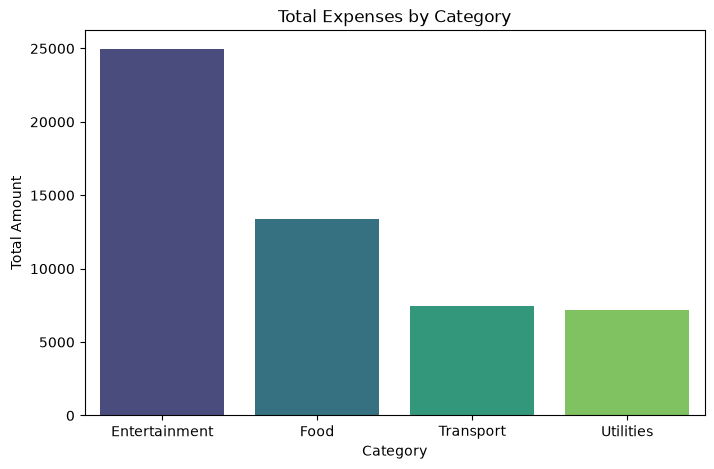

In [55]:
plt.figure(figsize=(8, 5))
sns.barplot(x=category_totals.index, y=category_totals.values,
            hue=category_totals.index, palette="viridis", legend=False)
plt.title("Total Expenses by Category")
plt.xlabel("Category")
plt.ylabel("Total Amount")
plt.show()

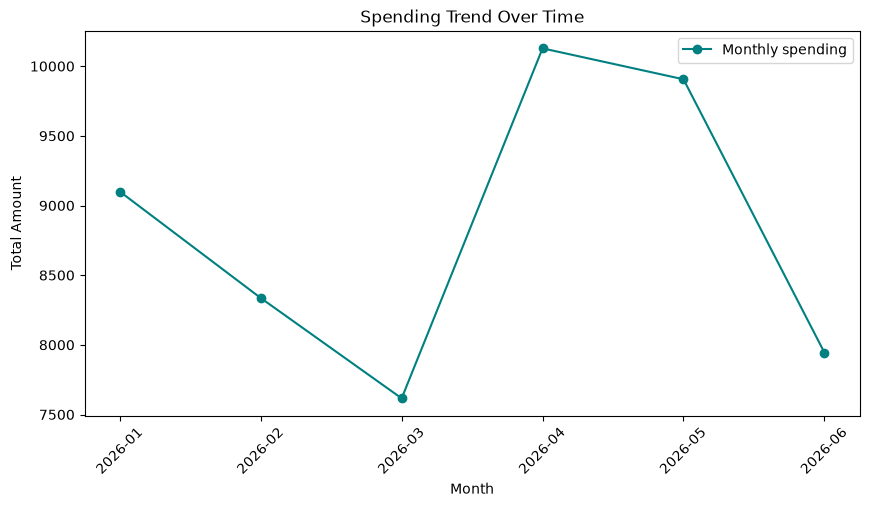

In [56]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_totals.index, monthly_totals.values,
         marker="o", color="teal", label="Monthly spending")
plt.title("Spending Trend Over Time")
plt.xlabel("Month")
plt.ylabel("Total Amount")
plt.legend()
plt.xticks(rotation=45)
plt.show()

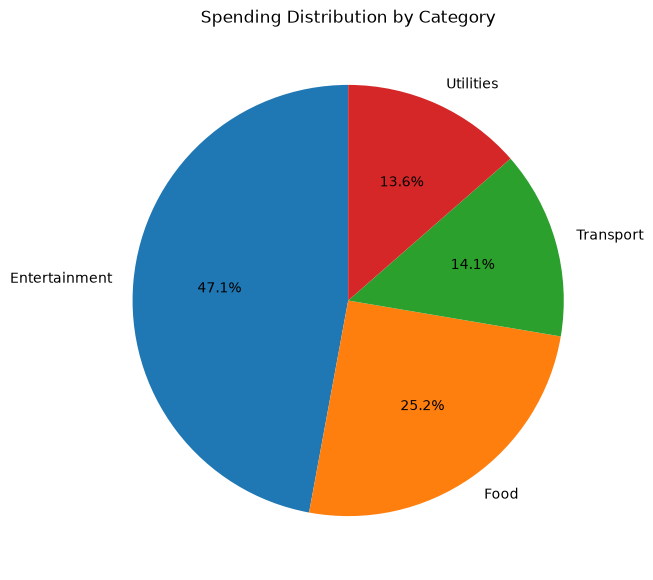

In [57]:
plt.figure(figsize=(7, 7))
plt.pie(category_totals.values, labels=category_totals.index,
        autopct="%1.1f%%", startangle=90)
plt.title("Spending Distribution by Category")
plt.show()

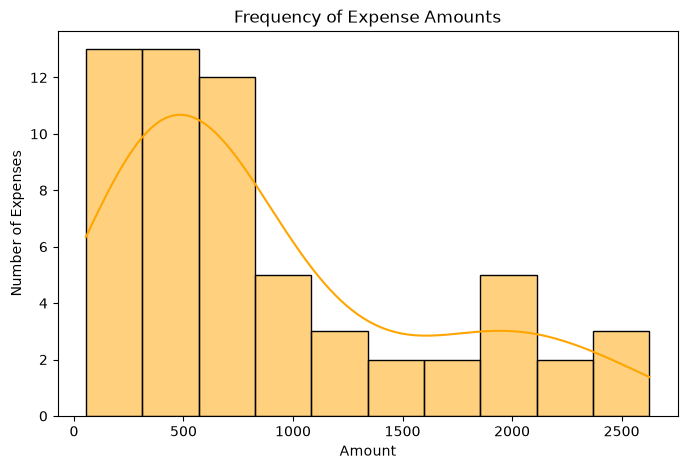

In [58]:
plt.figure(figsize=(8, 5))
sns.histplot(data["Amount"], bins=10, kde=True, color="orange")
plt.title("Frequency of Expense Amounts")
plt.xlabel("Amount")
plt.ylabel("Number of Expenses")
plt.show()

In [59]:
date = get_valid_date()

Enter date (YYYY-MM-DD): 2026-10-22


In [60]:
amount = get_valid_amount()

Enter amount:  5000


In [62]:
category = get_valid_category()

Category ['Food', 'Transport', 'Utilities', 'Entertainment']:  Entertainment


In [63]:
description = input("Enter description: ")

Enter description:  just expenses


In [64]:
tracker.add_expense(date, amount, category, description)

Expense added successfully!


In [65]:
tracker.generate_report()

===== EXPENSE REPORT =====
Total expenses : 58031.00
Average expense: 951.33
Top category   : Entertainment
Top month      : 2026-04
Transactions   : 61
